# SpaceX Launch Weather Analysis — DATA 304
**Vincent, Zach, Harrison**

Goal: Load Falcon Heavy launches, pull weather data, clean both datasets and match by UTC time.

## Load the launches


In [7]:
!pip install pandas



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [8]:
import pandas as pd
import requests
from pathlib import Path

# Works when the notebook is opened from the repository root or notebooks folder
root = Path.cwd()
if not (root / "data").exists():
    root = root.parent

launches = pd.read_csv(root / "/workspaces/DATA-304-Group-Project/launches_sample.csv")
print(launches.head())

   flight_number        launch_utc     launch_site         payload  \
0              1  2018-02-06 20:45  Kennedy LC-39A  Tesla Roadster   
1              2  2019-04-11 22:35  Kennedy LC-39A      Arabsat-6A   
2              3  2019-06-25 06:30  Kennedy LC-39A      USAF STP-2   

  launch_outcome                  source  
0        Success  Wikipedia Falcon Heavy  
1        Success  Wikipedia Falcon Heavy  
2        Success  Wikipedia Falcon Heavy  


## Clean the launch data
This uses the same steps as our DATA 304 assignments(fix strings, parse dates, remove missing times and duplicates.)

In [9]:
launches.columns = launches.columns.str.strip().str.lower()
launches["launch_site"] = launches["launch_site"].str.strip()
launches["launch_utc"] = pd.to_datetime(launches["launch_utc"], utc=True, errors="coerce")
print("Missing dates:", launches["launch_utc"].isna().sum())
print("Duplicate flights:", launches["flight_number"].duplicated().sum())
launches = launches.dropna(subset=["launch_utc"])
launches = launches.drop_duplicates(subset=["flight_number"])
launches = launches.sort_values("launch_utc")
launches

Missing dates: 0
Duplicate flights: 0


,flight_number,launch_utc,launch_site,payload,launch_outcome,source
0,1,2018-02-06 20:45:00+00:00,Kennedy LC-39A,Tesla Roadster,Success,Wikipedia Falcon Heavy
1,2,2019-04-11 22:35:00+00:00,Kennedy LC-39A,Arabsat-6A,Success,Wikipedia Falcon Heavy
2,3,2019-06-25 06:30:00+00:00,Kennedy LC-39A,USAF STP-2,Success,Wikipedia Falcon Heavy


## Get weather from Open-Meteo
 We request hourly historical weather at LC-39A (Florida), using UTC dates and times. Internet access is required.

In [10]:
url = "https://archive-api.open-meteo.com/v1/archive"
weather_parts = []
for day in launches["launch_utc"].dt.strftime("%Y-%m-%d").unique():
    params = {
        "latitude": 28.6084, "longitude": -80.6042,
        "start_date": day, "end_date": day,
        "hourly": "temperature_2m,relative_humidity_2m,precipitation,cloud_cover,wind_speed_10m,wind_gusts_10m",
        "temperature_unit": "fahrenheit", "wind_speed_unit": "mph",
        "precipitation_unit": "inch", "timezone": "UTC"
    }
    response = requests.get(url, params=params, timeout=40)
    response.raise_for_status()
    data = response.json()
    weather_parts.append(pd.DataFrame(data["hourly"]))

weather = pd.concat(weather_parts, ignore_index=True)
weather.head()

,time,temperature_2m,relative_humidity_2m,precipitation,cloud_cover,wind_speed_10m,wind_gusts_10m
0,2018-02-06T00:00,60.1,83,0.0,88,5.2,16.3
1,2018-02-06T01:00,58.3,88,0.0,4,4.4,8.7
2,2018-02-06T02:00,59.0,88,0.0,11,4.8,7.8
3,2018-02-06T03:00,60.2,87,0.0,4,5.0,8.3
4,2018-02-06T04:00,61.2,87,0.0,4,5.1,8.7


## Clean the weather timestamps
Both datasets need UTC datetime values so we can join them correctly.

In [11]:
weather["weather_utc"] = pd.to_datetime(weather["time"], utc=True, errors="coerce")
weather = weather.drop(columns="time")
weather = weather.dropna(subset=["weather_utc"])
weather = weather.drop_duplicates(subset=["weather_utc"])
weather = weather.sort_values("weather_utc")
print("Weather rows:", len(weather))
print("Weather timezone:", weather["weather_utc"].dt.tz)

Weather rows: 72
Weather timezone: UTC


## Match the launches and weather
merge_asof finds the nearest hourly weather record, but only if it is within 30 minutes.

In [12]:
all_data = pd.merge_asof(
    launches.sort_values("launch_utc"),
    weather.sort_values("weather_utc"),
    left_on="launch_utc", right_on="weather_utc",
    direction="nearest", tolerance=pd.Timedelta("30min")
)
all_data["minutes_apart"] = (
    (all_data["launch_utc"] - all_data["weather_utc"]).abs().dt.total_seconds() / 60
)
all_data

,flight_number,launch_utc,launch_site,payload,launch_outcome,source,temperature_2m,relative_humidity_2m,precipitation,cloud_cover,wind_speed_10m,wind_gusts_10m,weather_utc,minutes_apart
0,1,2018-02-06 20:45:00+00:00,Kennedy LC-39A,Tesla Roadster,Success,Wikipedia Falcon Heavy,70.6,79,0.0,16,10.0,17.7,2018-02-06 21:00:00+00:00,15.0
1,2,2019-04-11 22:35:00+00:00,Kennedy LC-39A,Arabsat-6A,Success,Wikipedia Falcon Heavy,76.0,74,0.0,8,7.6,15.9,2019-04-11 23:00:00+00:00,25.0
2,3,2019-06-25 06:30:00+00:00,Kennedy LC-39A,USAF STP-2,Success,Wikipedia Falcon Heavy,80.1,90,0.0,2,5.1,9.4,2019-06-25 06:00:00+00:00,30.0


## Check the results
Report data problems instead of silently deleting launches with missing weather.

In [13]:
print("Number of launches:", len(all_data))
print("Unmatched weather rows:", all_data["weather_utc"].isna().sum())
print("Duplicate flight numbers:", all_data["flight_number"].duplicated().sum())
print("Missing data by column:")
print(all_data.isna().sum())
print("More than 30 min apart:", (all_data["minutes_apart"] > 30).sum())

Number of launches: 3
Unmatched weather rows: 0
Duplicate flight numbers: 0
Missing data by column:
flight_number           0
launch_utc              0
launch_site             0
payload                 0
launch_outcome          0
source                  0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
cloud_cover             0
wind_speed_10m          0
wind_gusts_10m          0
weather_utc             0
minutes_apart           0
dtype: int64
More than 30 min apart: 0


## Saved the cleaned CSV

In [14]:
output = root / "data/processed/launch_weather.csv"
output.parent.mkdir(parents=True, exist_ok=True)
all_data.to_csv(output, index=False)
print("Saved to", output)

Saved to /workspaces/data/processed/launch_weather.csv


## 8. Simple chart
This is just an example. Three launches are not enough to draw conclusions about rocket safety.

In [16]:
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 26.8 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 33.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 28.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 34.3 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


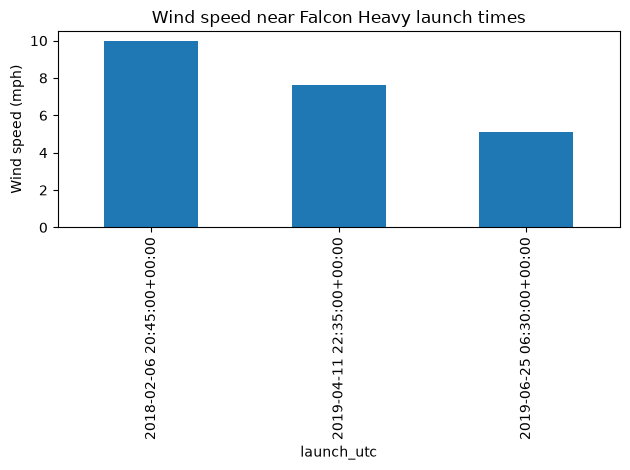

In [17]:
import matplotlib.pyplot as plt
all_data.plot(x="launch_utc", y="wind_speed_10m", kind="bar", legend=False)
plt.ylabel("Wind speed (mph)")
plt.title("Wind speed near Falcon Heavy launch times")
plt.tight_layout()
plt.show()